# DATA-500: Homework Assignment 8

## Instructions

- This homework assignment is worth **62** points. 
- Please strive for clarity and organization.
- **AI Usage**:
   - AI use is strictly **prohibited** for conceptual exercises.
   - For applied (Python) exercises, you may only use AI for **debugging**. Do not use AI to generate answers.
- **Due Date: November 13, 2026, by 11:59 PM.**

# Exercise 1 

In this exercise, we will practice refactoring concepts in analytics/data science tasks. You are given a dataset about employees, including information such as their department, salary, and years of experience. Your task is to analyze the dataset and then refactor the code for readability and efficiency. 

### Exercise 1(a) (3 points)

Load `pandas` and create a data-frame called `df` using the below data dictionary:

```
data = {
    'EmployeeID': [101, 102, 103, 104, 105],
    'Department': ['Engineering', 'HR', 'Engineering', 'Sales', 'HR'],
    'Salary': [70000, 50000, 75000, 45000, 60000],
    'YearsExperience': [5, 3, 7, 2, 4]
}
```

In [1]:

import pandas as pd

data = {
    'EmployeeID': [101, 102, 103, 104, 105],
    'Department': ['Engineering', 'HR', 'Engineering', 'Sales', 'HR'],
    'Salary': [70000, 50000, 75000, 45000, 60000],
    'YearsExperience': [5, 3, 7, 2, 4]
}

df = pd.DataFrame(data)
df


,EmployeeID,Department,Salary,YearsExperience
0,101,Engineering,70000,5
1,102,HR,50000,3
2,103,Engineering,75000,7
3,104,Sales,45000,2
4,105,HR,60000,4


### Exercise 1(b) (4 points)

The below code snippet has three functions the perform the following:

- `calculate_average_salary` computes the average salary by department.
- `calculate_median_experience` computes the median years of experience for each department.
- `high_earners` identifies employees who earn above a certain salary threshold. 


```
# Calculate average salary by department
def calculate_average_salary(dataframe):
    avg_salary = dataframe.groupby('Department')['Salary'].mean()
    return avg_salary

# Calculate median years of experience by department
def calculate_median_experience(dataframe):
    median_exp = dataframe.groupby('Department')['YearsExperience'].median()
    return median_exp

# Identify employees with salaries above a certain threshold
def high_earners(dataframe, threshold):
    return dataframe[dataframe['Salary'] > threshold]

```

Make sure the above function are working as expected by applying them to the `df` data-frame.

In [3]:

# Calculate average salary by department
def calculate_average_salary(dataframe):
    avg_salary = dataframe.groupby('Department')['Salary'].mean()
    return avg_salary

# Calculate median years of experience by department
def calculate_median_experience(dataframe):
    median_exp = dataframe.groupby('Department')['YearsExperience'].median()
    return median_exp

# Identify employees earning above a salary threshold
def high_earners(dataframe, threshold):
    return dataframe[dataframe['Salary'] > threshold]

# Test all three functions
print("Average Salary by Department:")
print(calculate_average_salary(df))

print("\nMedian Experience by Department:")
print(calculate_median_experience(df))

print("\nEmployees Earning More Than $60,000:")
print(high_earners(df, 60000))


Average Salary by Department:
Department
Engineering    72500.0
HR             55000.0
Sales          45000.0
Name: Salary, dtype: float64

Median Experience by Department:
Department
Engineering    6.0
HR             3.5
Sales          2.0
Name: YearsExperience, dtype: float64

Employees Earning More Than $60,000:
   EmployeeID   Department  Salary  YearsExperience
0         101  Engineering   70000                5
2         103  Engineering   75000                7


### Exercise 1(c) (6 points)

To improve code modularity, separate reusable components. Specifically:

- Add a helper function called `calculate_group_stat` to calculate group statistics (e.g., mean or median).
- Refactor the `calculate_average_salary` and `calculate_median_experience` functions to use the `calculate_group_stat` function.

Then, apply the refactored functions to the `df` data-frame

In [4]:

# Helper function to calculate group statistics
def calculate_group_stat(dataframe, column, statistic):
    return dataframe.groupby('Department')[column].agg(statistic)

# Refactored function for average salary
def calculate_average_salary(dataframe):
    return calculate_group_stat(dataframe, 'Salary', 'mean')

# Refactored function for median experience
def calculate_median_experience(dataframe):
    return calculate_group_stat(dataframe, 'YearsExperience', 'median')

# Apply the refactored functions to df
print("Average Salary by Department:")
print(calculate_average_salary(df))

print("\nMedian Experience by Department:")
print(calculate_median_experience(df))


Average Salary by Department:
Department
Engineering    72500.0
HR             55000.0
Sales          45000.0
Name: Salary, dtype: float64

Median Experience by Department:
Department
Engineering    6.0
HR             3.5
Sales          2.0
Name: YearsExperience, dtype: float64


### Exercise 1(d) (8 points)

To improve the readability of the functions, a description for each of the function. For example:

```
def high_earners(dataframe, threshold):
    """
    Identify employees with salaries above a certain threshold.

    Args:
        dataframe (pd.DataFrame): The DataFrame containing the data.
        threshold (int): The salary threshold to filter by.

    Returns:
        pd.DataFrame: A DataFrame of employees with salaries above the threshold.
    """
    return dataframe[dataframe['Salary'] > threshold]
```

Notice the function description.

In [5]:

# Helper function
def calculate_group_stat(dataframe, column, statistic):
    """
    Calculate a statistic for each department.

    Args:
        dataframe (pd.DataFrame): The employee data.
        column (str): The column to calculate.
        statistic (str): The statistic, such as mean or median.

    Returns:
        pd.Series: The statistic for each department.
    """
    return dataframe.groupby('Department')[column].agg(statistic)


# Average salary
def calculate_average_salary(dataframe):
    """
    Calculate the average salary for each department.

    Args:
        dataframe (pd.DataFrame): The employee data.

    Returns:
        pd.Series: Average salary by department.
    """
    return calculate_group_stat(dataframe, 'Salary', 'mean')


# Median experience
def calculate_median_experience(dataframe):
    """
    Calculate the median years of experience by department.

    Args:
        dataframe (pd.DataFrame): The employee data.

    Returns:
        pd.Series: Median experience by department.
    """
    return calculate_group_stat(dataframe, 'YearsExperience', 'median')


# High earners
def high_earners(dataframe, threshold):
    """
    Identify employees earning above a salary threshold.

    Args:
        dataframe (pd.DataFrame): The employee data.
        threshold (int): The salary cutoff.

    Returns:
        pd.DataFrame: Employees earning above the threshold.
    """
    return dataframe[dataframe['Salary'] > threshold]


### Exercise 1(e) (6 points)

Test the refactored code with test cases to ensure accuracy.

In [6]:

# Test average salary by department
avg_salary = calculate_average_salary(df)
assert avg_salary['Engineering'] == 72500
assert avg_salary['HR'] == 55000
assert avg_salary['Sales'] == 45000
print("Average salary tests passed!")

# Test median experience by department
median_exp = calculate_median_experience(df)
assert median_exp['Engineering'] == 6
assert median_exp['HR'] == 3.5
assert median_exp['Sales'] == 2
print("Median experience tests passed!")

# Test high earners
high_salary = high_earners(df, 60000)
assert len(high_salary) == 2
assert set(high_salary['EmployeeID']) == {101, 103}
print("High earners tests passed!")

# Test the helper function
group_stat = calculate_group_stat(df, 'Salary', 'mean')
assert group_stat.equals(avg_salary)
print("Helper function test passed!")

print("\nAll tests passed successfully!")


Average salary tests passed!
Median experience tests passed!
High earners tests passed!
Helper function test passed!

All tests passed successfully!


# Exercise 2

In this exercise, we will practice `polars` operations. Consider the `Electronic_sales_Sep2023-Sep2024.csv` data file. This dataset contains sales transaction records for an electronics company over a one-year period, spanning from September 2023 to September 2024. It includes detailed information about customer demographics, product types, and purchase behaviors. This is a brief description of each columns in the data file.

- `Customer ID`: Unique identifier for each customer.
- `Age`: Age of the customer (numeric)
- `Gender`: Gender of the customer (Male or Female)
- `Loyalty Member`: (Yes/No) (Values change by time, so pay attention to who cancelled and who signed up)
- `Product Type`: Type of electronic product sold (e.g., Smartphone, Laptop, Tablet)
- `SKU`: a unique code for each product.
- `Rating`: Customer rating of the product (1-5 stars) (Should have no Null Ratings)
- `Order Status`: Status of the order (Completed, Cancelled)
- `Payment Method`: Method used for payment (e.g., Cash, Credit Card, Paypal)
- `Total Price`: Total price of the transaction (numeric)
- `Unit Price`: Price per unit of the product (numeric)
- `Quantity`: Number of units purchased (numeric)
- `Purchase Date`: Date of the purchase (format: YYYY-MM-DD)
- `Shipping Type`: Type of shipping chosen (e.g., Standard, Overnight, Express)
- `Add-ons Purchased`: List of any additional items purchased (e.g., Accessories, Extended Warranty)
- `Add-on Total`: Total price of add-ons purchased (numeric)


### Exercise 2(a) (2 points)

Load `polars`, `matplotlib.pyplot` and `seaborn`.

In [7]:

import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns


### Exercise 2(b) (2 points)

Read the `Electronic_sales_Sep2023-Sep2024.csv` data file and create a data frame called `df`. Report the shape of `df`.

In [8]:

df = pl.read_csv("Electronic_sales_Sep2023-Sep2024.csv")

print("Shape of DataFrame:", df.shape)


Shape of DataFrame: (20000, 16)


### Exercise 2(c) (3 points)

Report the number of unique `Customer ID`.

In [9]:

unique_customers = df["Customer ID"].n_unique()

print("Number of unique customers:", unique_customers)


Number of unique customers: 12136


### Exercise 2(d) (3 points)

Create a column called `Total_Spending`, which is the sum of `Total Price` and `Add-on Total`.

In [10]:

df = df.with_columns(
    (pl.col("Total Price") + pl.col("Add-on Total")).alias("Total_Spending")
)

print(df.select(["Total Price", "Add-on Total", "Total_Spending"]).head())


shape: (5, 3)
┌─────────────┬──────────────┬────────────────┐
│ Total Price ┆ Add-on Total ┆ Total_Spending │
│ ---         ┆ ---          ┆ ---            │
│ f64         ┆ f64          ┆ f64            │
╞═════════════╪══════════════╪════════════════╡
│ 5538.33     ┆ 40.21        ┆ 5578.54        │
│ 741.09      ┆ 26.09        ┆ 767.18         │
│ 1855.84     ┆ 0.0          ┆ 1855.84        │
│ 3164.76     ┆ 60.16        ┆ 3224.92        │
│ 41.5        ┆ 35.56        ┆ 77.06          │
└─────────────┴──────────────┴────────────────┘


### Exercise 2(e) (3 points)

Compute the average `Total_Spending` by `Customer ID`. Report the `Customer ID`s with the smallest and largest average `Total_Spending`.

In [11]:

avg_spending = df.group_by("Customer ID").agg(
    pl.col("Total_Spending").mean().alias("Average_Spending")
)

smallest = avg_spending.sort("Average_Spending").head(1)
largest = avg_spending.sort("Average_Spending", descending=True).head(1)

print("Customer with smallest average spending:")
print(smallest)

print("\nCustomer with largest average spending:")
print(largest)


Customer with smallest average spending:
shape: (1, 2)
┌─────────────┬──────────────────┐
│ Customer ID ┆ Average_Spending │
│ ---         ┆ ---              │
│ i64         ┆ f64              │
╞═════════════╪══════════════════╡
│ 5419        ┆ 20.75            │
└─────────────┴──────────────────┘

Customer with largest average spending:
shape: (1, 2)
┌─────────────┬──────────────────┐
│ Customer ID ┆ Average_Spending │
│ ---         ┆ ---              │
│ i64         ┆ f64              │
╞═════════════╪══════════════════╡
│ 12611       ┆ 11655.12         │
└─────────────┴──────────────────┘


### Exercise 2(f) (5 points)

Report the most popular `Product Type` among `Male` and `Female`.

In [12]:

# Count product types by gender
product_counts = (
    df.group_by(["Gender", "Product Type"])
    .agg(pl.len().alias("Count"))
)

# Find the most popular product for each gender
most_popular = (
    product_counts
    .sort(["Gender", "Count"], descending=[False, True])
    .group_by("Gender", maintain_order=True)
    .head(1)
)

print(most_popular)


shape: (3, 3)
┌────────┬──────────────┬───────┐
│ Gender ┆ Product Type ┆ Count │
│ ---    ┆ ---          ┆ ---   │
│ str    ┆ str          ┆ u32   │
╞════════╪══════════════╪═══════╡
│ #N/A   ┆ Laptop       ┆ 1     │
│ Female ┆ Smartphone   ┆ 2980  │
│ Male   ┆ Smartphone   ┆ 2998  │
└────────┴──────────────┴───────┘


### Exercise 2(g) (4 points)

Do loyal customers spend more? 

In [13]:

# Compare average spending by loyalty membership
loyalty_spending = (
    df.group_by("Loyalty Member")
    .agg(
        pl.col("Total_Spending").mean().alias("Average_Spending"),
        pl.len().alias("Transactions")
    )
    .sort("Loyalty Member")
)

print(loyalty_spending)


shape: (2, 3)
┌────────────────┬──────────────────┬──────────────┐
│ Loyalty Member ┆ Average_Spending ┆ Transactions │
│ ---            ┆ ---              ┆ ---          │
│ str            ┆ f64              ┆ u32          │
╞════════════════╪══════════════════╪══════════════╡
│ No             ┆ 3254.202114      ┆ 15657        │
│ Yes            ┆ 3199.751976      ┆ 4343         │
└────────────────┴──────────────────┴──────────────┘


### Exercise 2(h) (5 points)

Does age play a role on the total amount of the transaction?

Correlation between Age and Total Spending: 0.002968828504897639


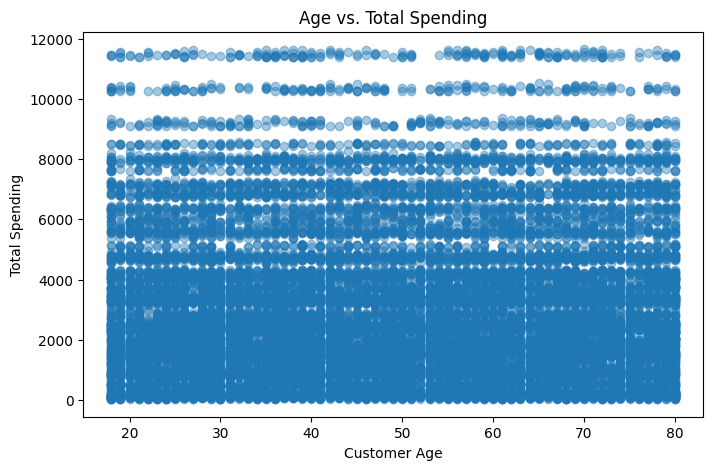

In [15]:

# Calculate correlation between age and spending
correlation = df.select(
    pl.corr("Age", "Total_Spending")
).item()

print("Correlation between Age and Total Spending:", correlation)

# Create scatterplot without converting to pandas
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Age"].to_list(),
    df["Total_Spending"].to_list(),
    alpha=0.4
)

plt.title("Age vs. Total Spending")
plt.xlabel("Customer Age")
plt.ylabel("Total Spending")
plt.show()



The correlation between age and total spending is approximately 0.003, indicating almost no linear relationship. This suggests that customer age does not meaningfully predict the total amount spent per transaction in this dataset.

# Exercise 3

In this exercise, we will review the design and refactoring concepts from Chapter 8. Answer in your own words (no AI).


### Exercise 3(a) (3 points)

Consider the following function:

```
THRESHOLD = 60000

def flag_high_earners(dataframe):
    dataframe['HighEarner'] = dataframe['Salary'] > THRESHOLD
    return dataframe
```

A colleague changes `THRESHOLD` elsewhere in the module, and the results of `flag_high_earners` silently change. Which statement best describes the design problem and its fix?

A. The function has low cohesion; it should be split into two functions, one for each column it touches.

B. The function is tightly coupled to a hidden module-level value that does not appear in its signature; pass `threshold` as an argument (dependency injection) instead.

C. The function lacks a docstring; adding a description of the `THRESHOLD` value removes the problem.

D. The function is a code smell because it is short; it should be inlined into the calling code.


B

### Exercise 3(b) (5 points)

A teammate asks you to restructure a long, untested notebook function so that it is easier to read. They suggest rewriting it from scratch in one large step, and also fixing a few bugs they noticed along the way.

1. Using the definition of refactoring, explain why this plan is risky. (2 points)
2. Describe the steps you would take instead, including what you would do first since there are no tests. (3 points)


**Your answer here:**

1. Refactoring means improving the structure of code without changing what it does. Rewriting everything at once while also fixing bugs is risky because it can introduce new errors and make it difficult to identify what caused them.

2. I would first create tests for the existing function to document its current behavior. Then I would make small changes to improve readability, such as renaming variables, removing repeated code, and breaking up long sections. I would run the tests after each change to make sure the function still works the same way. Once the refactoring is complete, I would address any bugs separately and test those fixes.